# Telecom Churn: Improved Pipeline (v2)

Notebook 01 is the analysis I submitted. This notebook fixes its weak points:

1. **Leak-free cleaning.** The cleaning steps are now a scikit-learn transformer inside a pipeline, so medians and
   category codes are learned from training data only.
2. **5-fold cross-validation** on the training split, so every score comes with a spread (mean ± std).
3. **Baselines:** a simple device-age rule and logistic regression, to see what XGBoost adds.
4. **Light tuning** of XGBoost with Optuna (cross-validation on the training split only).
5. **Extra features:** four small groups of ratio features, kept only if they pass a rule set in advance.
6. **A better profit analysis:** the threshold is picked on validation data and reported on the test set,
   offers only work for some churners (success rate), and every result is compared with "offer everyone".
7. **A calibration check:** do the predicted probabilities match the real churn rates?

The test set is the same 20,000 customers as in notebook 01, and it is only used for final numbers.
The reusable code is in `src/churn/`; `scripts/` has the tuning, feature check, training and scoring scripts.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from churn.data import load_data, split_train_test
from churn.explain import explain_customers
from churn.models import (SEED, DeviceAgeRule, cross_val_oof, load_params, make_logreg_pipeline,
                          make_xgb_pipeline)
from churn.preprocessing import FEATURE_GROUPS
from churn.profit import (LIFETIME_MONTHS, OFFER_COST, SUCCESS_RATE, best_threshold, campaign_profit,
                          prevalence_weights)

DATA_DIR = PROJECT_ROOT / "data" / "telecom"
FIG_DIR = PROJECT_ROOT / "outputs" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TUNED_PARAMS = PROJECT_ROOT / "configs" / "xgb_tuned_params.json"
TRIALS_CSV = PROJECT_ROOT / "outputs" / "tuning" / "optuna_trials.csv"
FEATURES_CSV = PROJECT_ROOT / "outputs" / "features" / "feature_groups_cv.csv"
pd.set_option("display.max_colwidth", 90)

In [2]:
df = load_data(DATA_DIR)
X_train, X_test, y_train, y_test = split_train_test(df)
print(f"Train: {len(X_train):,} customers   Test: {len(X_test):,} customers (same as notebook 01)")
print(f"Churn rate: train {y_train.mean():.2%}, test {y_test.mean():.2%}")

Train: 80,000 customers   Test: 20,000 customers (same as notebook 01)
Churn rate: train 49.56%, test 49.56%


## 2. Leak-free cleaning

In notebook 01 the medians used to fill missing values were computed on all 100,000 customers before the
train/test split, so a little information from the test customers was used in training.
`ChurnPreprocessor` (in `src/churn/preprocessing.py`) applies exactly the same rules, but learns the medians,
category codes and constant columns in `fit()`, which the pipeline only calls on training data.
Fitted on all customers, it gives exactly the same table as notebook 01.

First check: the original XGBoost settings with the leak-free cleaning.

In [3]:
leak_free = make_xgb_pipeline().fit(X_train, y_train)
prob_leak_free = leak_free.predict_proba(X_test)[:, 1]
print(f"Test ROC-AUC with leak-free cleaning: {roc_auc_score(y_test, prob_leak_free):.4f}")
print("Test ROC-AUC in notebook 01:         0.6952")

Test ROC-AUC with leak-free cleaning: 0.6956
Test ROC-AUC in notebook 01:         0.6952


The difference is tiny, which is expected: medians over 100,000 rows barely move when 20,000 rows are left
out. The result in notebook 01 was not inflated by the leak, but the setup is now correct and can be
cross-validated.

## 3. Cross-validation and baselines

Four models, each scored with 5-fold cross-validation on the training split (the whole pipeline, cleaning
included, is refitted in every fold) and then once on the test set:

- **Rule:** flag a customer if their device is older than 1 year (no learning, from the EDA in notebook 01).
- **Logistic regression:** scaled numeric columns + one-hot text columns.
- **XGBoost, original settings** from notebook 01.
- **XGBoost, tuned** with Optuna (section 4).

The out-of-fold probabilities (each customer scored by a model that never saw them) are kept for section 6.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
tuned_params = load_params(TUNED_PARAMS)

models = {
    "Rule: device older than 1 year": DeviceAgeRule(days=365),
    "Logistic regression": make_logreg_pipeline(),
    "XGBoost (original settings)": make_xgb_pipeline(),
    "XGBoost (tuned)": make_xgb_pipeline(tuned_params),
}

rows, oof_probs, test_probs = [], {}, {}
for name, model in models.items():
    fold_auc, oof = cross_val_oof(model, X_train, y_train, cv)
    model.fit(X_train, y_train)
    prob = model.predict_proba(X_test)[:, 1]
    pred = (prob >= 0.5).astype(int)
    oof_probs[name], test_probs[name] = oof, prob
    rows.append({
        "model": name,
        "cv_auc_mean": fold_auc.mean(),
        "cv_auc_std": fold_auc.std(),
        "test_auc": roc_auc_score(y_test, prob),
        "test_accuracy": accuracy_score(y_test, pred),
        "precision_churn": precision_score(y_test, pred),
        "recall_churn": recall_score(y_test, pred),
    })

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(4)

,cv_auc_mean,cv_auc_std,test_auc,test_accuracy,precision_churn,recall_churn
model,,,,,,
Rule: device older than 1 year,0.5484,0.0042,0.5442,0.5446,0.5440,0.5009
Logistic regression,0.6288,0.0024,0.6320,0.5972,0.5937,0.5936
XGBoost (original settings),0.6961,0.0043,0.6956,0.6384,0.6322,0.6466
XGBoost (tuned),0.6972,0.0053,0.6972,0.6383,0.6324,0.6453


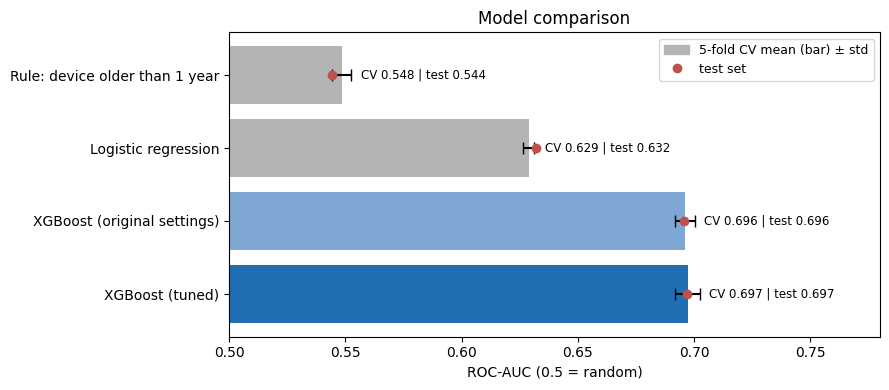

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
names = comparison.index[::-1]
ax.barh(names, comparison.loc[names, "cv_auc_mean"], xerr=comparison.loc[names, "cv_auc_std"],
        color=["#B4B4B4", "#B4B4B4", "#7FA7D3", "#1F6FB2"][::-1], capsize=4, label="5-fold CV (mean ± std)")
ax.scatter(comparison.loc[names, "test_auc"], names, color="#C0504D", zorder=3, label="test set")
for i, name in enumerate(names):
    row = comparison.loc[name]
    right = max(row["cv_auc_mean"] + row["cv_auc_std"], row["test_auc"])
    ax.text(right + 0.004, i, f"CV {row['cv_auc_mean']:.3f} | test {row['test_auc']:.3f}",
            va="center", fontsize=8.5)
ax.set_xlim(0.5, 0.78)
ax.set_xlabel("ROC-AUC (0.5 = random)")
ax.set_title("Model comparison")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#B4B4B4", label="5-fold CV mean (bar) ± std"),
                   plt.Line2D([], [], marker="o", color="#C0504D", linestyle="", label="test set")],
          loc="upper right", fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "v2_model_comparison.png", dpi=150)
plt.show()

**What this shows**

- The device-age rule is only a little better than random (0.55). Device age matters, but on its own it is
  not enough.
- Logistic regression reaches 0.63 and XGBoost about 0.70, so the non-linear model clearly helps on this data.
- Tuning adds about 0.001 in cross-validation (0.696 to 0.697) and 0.0016 on the test set. That is smaller than
  the spread between folds (± 0.005), so the tuned model is not clearly better. I keep the tuned settings
  because they are not worse, but the original settings were already close to the best. Section 5 adds
  features on top of them.
- For every model the CV score and the test score are close, so the single test split in notebook 01 was not a
  lucky split.

## 4. Tuning XGBoost with Optuna

`scripts/tune.py` searched 8 XGBoost settings (number of trees, learning rate, depth, sampling and
regularisation) for 30 trials. Each trial is scored with 3-fold cross-validation on the training split
only, so the test set plays no part. The sampler has a fixed seed, and the first trial is the original
setting, so tuning can only match or beat it. It took about 27 minutes on 2 CPU cores, so the result is
saved and loaded here. To run it again: `python scripts/tune.py --n-trials 30 --folds 3`.

In [6]:
tuning = json.loads(TUNED_PARAMS.read_text())
print(f"Best 3-fold CV ROC-AUC: {tuning['cv_auc']:.4f}  (original settings: {tuning['original_settings_cv_auc']:.4f})")
pd.Series(tuning["params"], name="tuned value").to_frame()

Best 3-fold CV ROC-AUC: 0.6962  (original settings: 0.6932)


,tuned value
n_estimators,900.000000
learning_rate,0.015615
max_depth,7.000000
min_child_weight,2.993441
subsample,0.754864
colsample_bytree,0.623293
reg_lambda,0.893825
gamma,1.624313


In [7]:
trials = pd.read_csv(TRIALS_CSV)
trials.sort_values("cv_auc", ascending=False).head(5).round(4)

,number,cv_auc,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_lambda,params_subsample
29,29,0.6962,0.6233,1.6243,0.0156,7,2.9934,900,0.8938,0.7549
26,26,0.6960,0.5924,2.2219,0.0139,8,1.3326,1000,0.1889,0.7434
25,25,0.6957,0.6383,2.1860,0.0135,8,1.4132,1000,0.3665,0.7996
22,22,0.6956,0.6412,3.4062,0.0214,7,1.2907,900,0.8699,0.8154
28,28,0.6956,0.6756,2.5085,0.0100,8,2.3643,950,0.1772,0.6908


The best trial reached 0.6962 in 3-fold CV, against 0.6932 for the original settings (+0.003). The best
settings use more trees with a smaller learning rate, and a bit more regularisation (`gamma`,
`min_child_weight`). The 3-fold scores are lower than the 5-fold scores in section 3 because each model is
trained on less data. In the 5-fold check the gain shrinks to about 0.001, so tuning helps very little here.

## 5. Extra features

Tuning barely helped, so the next thing to try is better inputs. I wrote four small groups of ratio
features (`FEATURE_GROUPS` in `src/churn/preprocessing.py`). Trees can only split one column at a time, so a
ratio can be hard for them to build from two raw columns.

| Group | Features | Idea |
|---|---|---|
| device | device age / tenure, phones per year, active / unique subscribers | still on the first phone? |
| call_quality | dropped / attempted calls, dropped / placed voice calls, completed / attempted, care calls per call | bad service |
| billing | overage / revenue, plan charge / revenue, revenue per minute | bill shock |
| usage_trend | recent usage / lifetime average, same for revenue, usage change / 3-month usage | using the phone less |

`scripts/feature_check.py` scores the original features, each group on its own and all groups together with
5-fold CV on the training split (same folds, tuned settings). It takes about 10 minutes, so the result is
loaded here.

The rule for using the extra features was set before running the check: the "all groups" setting must beat
the original features on average by more than 2 standard errors (from the 5 fold differences), and in at
least 4 of the 5 folds.

In [8]:
features_cv = pd.read_csv(FEATURES_CSV).set_index("setting")
fold_cols = [c for c in features_cv.columns if c.startswith("fold_")]
gain = features_cv[fold_cols].sub(features_cv.loc["original", fold_cols], axis=1)
feature_table = pd.DataFrame({
    "cv_auc_mean": features_cv[fold_cols].mean(axis=1),
    "gain_vs_original": gain.mean(axis=1),
    "gain_std_error": gain.std(axis=1) / np.sqrt(len(fold_cols)),
    "folds_better": (gain > 0).sum(axis=1),
})
feature_table.round(4)

,cv_auc_mean,gain_vs_original,gain_std_error,folds_better
setting,,,,
original,0.6972,0.0000,0.0000,0
+ device,0.6983,0.0011,0.0006,4
+ call_quality,0.6976,0.0004,0.0003,4
+ billing,0.6986,0.0014,0.0007,4
+ usage_trend,0.7019,0.0046,0.0006,5
+ all groups,0.7028,0.0055,0.0010,5


In [9]:
all_groups = feature_table.loc["+ all groups"]
use_extra = (all_groups["gain_vs_original"] > 2 * all_groups["gain_std_error"]) and (all_groups["folds_better"] >= 4)
print(f"Gain {all_groups['gain_vs_original']:+.4f} (2 standard errors = {2 * all_groups['gain_std_error']:.4f}), "
      f"better in {all_groups['folds_better']:.0f} of {len(fold_cols)} folds -> use extra features: {use_extra}")

final_name = "XGBoost (tuned)"
if use_extra:
    final_name = "XGBoost (tuned + extra features)"
    model = make_xgb_pipeline(tuned_params, extra_features=tuple(FEATURE_GROUPS))
    fold_auc, oof_probs[final_name] = cross_val_oof(model, X_train, y_train, cv)
    models[final_name] = model.fit(X_train, y_train)
    test_probs[final_name] = model.predict_proba(X_test)[:, 1]
    print(f"Same CV check inside the notebook: {fold_auc.mean():.4f} (file: {all_groups['cv_auc_mean']:.4f})")
    print(f"Test ROC-AUC: {roc_auc_score(y_test, test_probs[final_name]):.4f} "
          f"(without extra features: {roc_auc_score(y_test, test_probs['XGBoost (tuned)']):.4f})")
print(f"Final model for the rest of the notebook: {final_name}")

Gain +0.0055 (2 standard errors = 0.0020), better in 5 of 5 folds -> use extra features: True


Same CV check inside the notebook: 0.7028 (file: 0.7028)
Test ROC-AUC: 0.7026 (without extra features: 0.6972)
Final model for the rest of the notebook: XGBoost (tuned + extra features)


- The usage trend group gives most of the gain (+0.0046). The other groups add 0.0004 to 0.0014 each.
- All four groups together add +0.0055 in CV (0.697 to 0.703) and are better in all 5 folds, so they pass
  the rule. On the test set the gain is about the same (0.6972 to 0.7026).
- That is about five times the gain from tuning. Comparing the last months with the customer's own history
  tells the model more than any of the settings did.
- From here on the final model is XGBoost with the tuned settings and the extra features.

## 6. Profit analysis, done properly

### 6.1 What changed

Notebook 01 valued a saved churner at 12 months of revenue **and** the $400 cost of replacing them, assumed
every offered churner stays, and picked the threshold on the same test set it reported. Here:

| Customer | Offer sent | No offer |
|---|---|---|
| Would churn | success_rate × value_saved − offer cost | 0 |
| Would stay | − offer cost | 0 |

- Profit is measured against running no campaign at all, so each customer is counted once.
- `value_saved` = average monthly revenue in the training data × 12 months (about $705); offer cost $35,
  as in the proposal.
- `success_rate` is the share of offered churners who really stay. It is unknown, so several values are
  shown; 30% is used as the middle case.
- The threshold is picked on the **out-of-fold** probabilities of the training split and then applied
  unchanged to the test set.

In [10]:
value_saved = X_train["rev_Mean"].mean() * LIFETIME_MONTHS
oof, prob = oof_probs[final_name], test_probs[final_name]
device_rule = (X_test["eqpdays"] > 365).to_numpy()
print(f"value_saved = ${value_saved:,.2f}, offer cost = ${OFFER_COST:.0f}, middle success rate = {SUCCESS_RATE:.0%}")


def compare_rules(success_rate, churn_rate=None):
    # churn_rate=None uses the data as it is (about 50% churn); otherwise rows are re-weighted
    w_train = None if churn_rate is None else prevalence_weights(y_train, churn_rate)
    w_test = np.ones(len(y_test)) if churn_rate is None else prevalence_weights(y_test, churn_rate)
    thr = best_threshold(y_train, oof, value_saved, OFFER_COST, success_rate, w_train)
    rules = {
        "Model, threshold picked on validation": prob >= thr,
        "Offer everyone": np.ones(len(prob), dtype=bool),
        "Device older than 1 year": device_rule,
        "Model, threshold 0.5": prob >= 0.5,
        "Model, top 20% of scores": prob >= np.quantile(prob, 0.8),
        "Offer nobody": np.zeros(len(prob), dtype=bool),
    }
    rows = []
    for name, contact in rules.items():
        total = campaign_profit(y_test, contact, value_saved, OFFER_COST, success_rate, w_test)
        rows.append({"rule": name,
                     "contacted_share": np.average(contact, weights=w_test),
                     "profit_per_1000_customers": total / w_test.sum() * 1000})
    return thr, pd.DataFrame(rows).set_index("rule")

value_saved = $705.22, offer cost = $35, middle success rate = 30%


### 6.2 Main case: 30% success rate, churn rate as in the data

In [11]:
thr_main, main_table = compare_rules(SUCCESS_RATE)
print(f"Threshold picked on validation data: {thr_main:.3f}")
main_table.round({"contacted_share": 3, "profit_per_1000_customers": 0})

Threshold picked on validation data: 0.180


,contacted_share,profit_per_1000_customers
rule,,
"Model, threshold picked on validation",0.963,70177.0
Offer everyone,1.000,69852.0
Device older than 1 year,0.456,36549.0
"Model, threshold 0.5",0.499,50035.0
"Model, top 20% of scores",0.200,24714.0
Offer nobody,0.000,0.0


- The threshold picked on validation data is 0.180, so 96.3% of test customers get the offer.
- Profit is $70,177 per 1,000 customers, against $69,852 for offering everyone. The difference is only $325
  per 1,000 customers (0.5%).
- The usual 0.5 cut-off contacts half the customers and makes $50,035. The device-age rule makes $36,549.
- So in this setup the model adds almost nothing over offering everyone. The reason is the data: half of the
  customers churn, so even a random customer is worth the offer (0.50 × 0.3 × $705 = $105 expected value
  against a $35 cost).

### 6.3 How much does the success rate matter?

In [12]:
success_rates = [0.1, 0.2, 0.3, 0.5, 1.0]


def sensitivity(churn_rate=None):
    rows = []
    for s in success_rates:
        thr, table = compare_rules(s, churn_rate)
        rows.append({
            "success_rate": s,
            "threshold": thr,
            "contacted_share": table.iloc[0]["contacted_share"],
            "model": table.iloc[0]["profit_per_1000_customers"],
            "offer_everyone": table.loc["Offer everyone", "profit_per_1000_customers"],
            "device_rule": table.loc["Device older than 1 year", "profit_per_1000_customers"],
        })
    return pd.DataFrame(rows).set_index("success_rate")


sens_data = sensitivity()
sens_data.round({"threshold": 3, "contacted_share": 3, "model": 0, "offer_everyone": 0, "device_rule": 0})

,threshold,contacted_share,model,offer_everyone,device_rule
success_rate,,,,,
0.1,0.485,0.533,5035.0,-49.0,1535.0
0.2,0.245,0.912,35871.0,34901.0,19042.0
0.3,0.180,0.963,70177.0,69852.0,36549.0
0.5,0.130,0.988,139820.0,139753.0,71563.0
1.0,0.045,1.000,314509.0,314505.0,159098.0


### 6.4 With a realistic churn rate

The data is about 50% churners, but a real operator loses only a few percent of customers a month
(2–3% for US wireless in the late 1990s according to Mozer et al., 1999; about 0.9% for AT&T postpaid
phones in Q3 2025, as reported by PhoneArena). Below, rows are re-weighted so that 2% of
customers churn, and the threshold is picked again on the re-weighted validation data. This assumes the
balanced dataset was made by sampling, so the model's ranking still holds.

In [13]:
REAL_CHURN_RATE = 0.02
sens_real = sensitivity(REAL_CHURN_RATE)
sens_real.round({"threshold": 3, "contacted_share": 4, "model": 0, "offer_everyone": 0, "device_rule": 0})

,threshold,contacted_share,model,offer_everyone,device_rule
success_rate,,,,,
0.1,0.950,0.0000,1.0,-33590.0,-13795.0
0.2,0.925,0.0002,8.0,-32179.0,-13089.0
0.3,0.910,0.0007,26.0,-30769.0,-12382.0
0.5,0.850,0.0050,155.0,-27948.0,-10969.0
1.0,0.710,0.0457,880.0,-20896.0,-7437.0


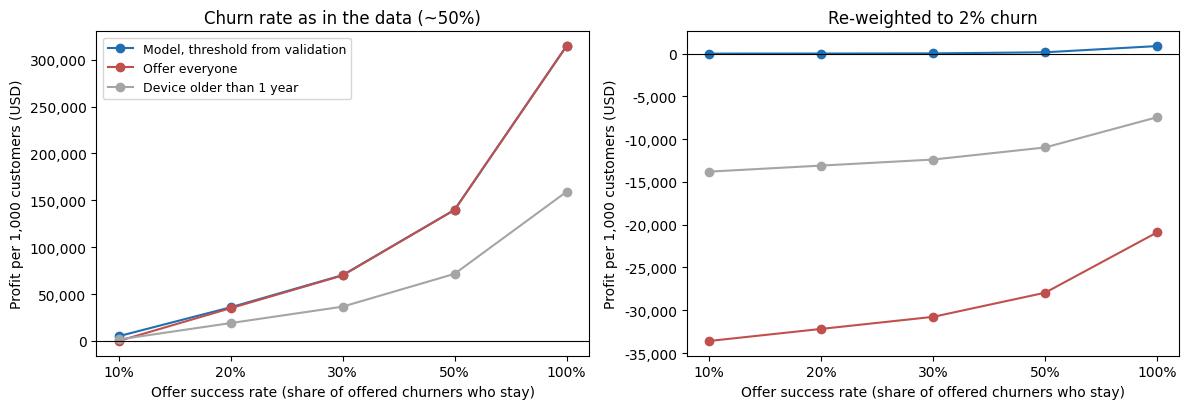

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, data, title in [(axes[0], sens_data, "Churn rate as in the data (~50%)"),
                        (axes[1], sens_real, f"Re-weighted to {REAL_CHURN_RATE:.0%} churn")]:
    x = [f"{s:.0%}" for s in data.index]
    ax.plot(x, data["model"], marker="o", color="#1F6FB2", label="Model, threshold from validation")
    ax.plot(x, data["offer_everyone"], marker="o", color="#C0504D", label="Offer everyone")
    ax.plot(x, data["device_rule"], marker="o", color="#A5A5A5", label="Device older than 1 year")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(title)
    ax.set_xlabel("Offer success rate (share of offered churners who stay)")
    ax.set_ylabel("Profit per 1,000 customers (USD)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "v2_profit_by_success_rate.png", dpi=150)
plt.show()

At a 2% churn rate, how much could an offer cost and still pay off? For each tenth of test customers
(group 1 = highest scores), the break-even offer cost is the group's real churn rate × success rate ×
value_saved.

In [15]:
w_real = prevalence_weights(y_test, REAL_CHURN_RATE)
risk_group = 10 - pd.qcut(pd.Series(prob).rank(method="first"), 10, labels=False).to_numpy()
real_rate = (pd.Series(w_real * y_test.to_numpy()).groupby(risk_group).sum()
             / pd.Series(w_real).groupby(risk_group).sum())
breakeven = pd.DataFrame({
    "churn_rate_at_2pct": real_rate,
    "max_offer_cost_30pct_success": real_rate * 0.3 * value_saved,
    "max_offer_cost_100pct_success": real_rate * 1.0 * value_saved,
})
breakeven.index.name = "risk_group"
breakeven.head(5).round({"churn_rate_at_2pct": 4, "max_offer_cost_30pct_success": 2,
                         "max_offer_cost_100pct_success": 2})

,churn_rate_at_2pct,max_offer_cost_30pct_success,max_offer_cost_100pct_success
risk_group,,,
1,0.0799,16.91,56.35
2,0.0446,9.43,31.44
3,0.0320,6.77,22.55
4,0.0261,5.52,18.42
5,0.0220,4.65,15.49


**What the profit analysis says**

- With the data as it is (half churners), the model only clearly beats "offer everyone" when offers rarely
  work. At a 10% success rate it makes $5,035 per 1,000 customers while offering everyone loses $49. From
  30% up, both are about the same.
- With a realistic 2% churn rate, offering everyone loses money at every success rate ($21k to $34k per 1,000
  customers), and so does the device-age rule. The best choice for the model is to contact almost nobody:
  even at 100% success it contacts only 4.6% of customers and makes $880 per 1,000.
- The break-even table shows why. Even in the top 10% of scores only about 8% of customers churn at a 2%
  base rate, so an offer there can cost at most about $17 (30% success) to $56 (100% success). The $35 offer
  from the proposal only pays off for the top group, and only if more than about 60% of offers work.
- So the model is useful for ranking customers, but whether a campaign makes money depends on the real churn
  rate, the offer cost and the success rate. These numbers would have to come from Company A, ideally from a
  small pilot that measures the success rate.

## 7. What drives the final model (SHAP)

Same check as in notebook 01, on 1,000 random test customers, plus the top reasons and the suggested offer
for the five highest-risk customers in that sample (the same logic as `scripts/score_customers.py`).

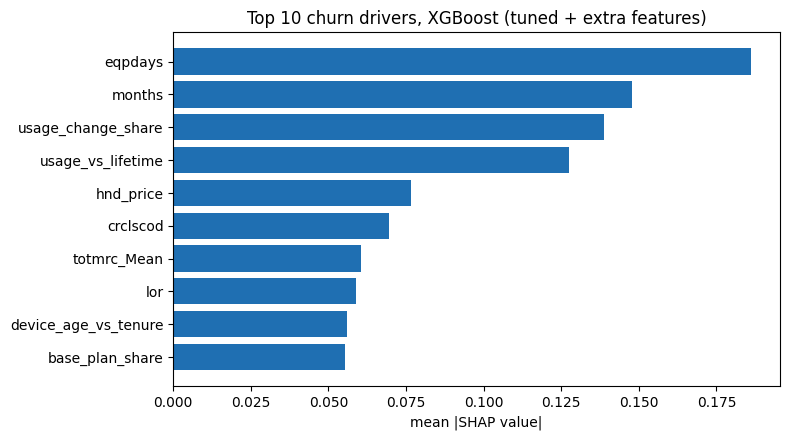

In [16]:
final_model = models[final_name]
prep, xgb_model = final_model.named_steps["prep"], final_model.named_steps["model"]
X_sample = X_test.sample(n=1000, random_state=SEED)
shap_values = shap.TreeExplainer(xgb_model).shap_values(prep.transform(X_sample))
importance = pd.Series(np.abs(shap_values).mean(axis=0), index=prep.get_feature_names_out())
importance = importance.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
top10 = importance.head(10)[::-1]
ax.barh(top10.index, top10.values, color="#1F6FB2")
ax.set_xlabel("mean |SHAP value|")
ax.set_title(f"Top 10 churn drivers, {final_name}")
plt.tight_layout()
plt.savefig(FIG_DIR / "v2_shap_importance.png", dpi=150)
plt.show()

In [17]:
reasons = explain_customers(shap_values, prep.clean(X_sample))
sample_prob = pd.Series(final_model.predict_proba(X_sample)[:, 1], index=X_sample.index, name="churn_probability")
top5 = sample_prob.sort_values(ascending=False).head(5).index
pd.concat([sample_prob.loc[top5].round(3),
           reasons.loc[top5, ["driver_1", "driver_2", "driver_3", "suggested_offer"]]], axis=1)

,churn_probability,driver_1,driver_2,driver_3,suggested_offer
51064,0.921,usage_change_share,usage_vs_lifetime,eqpdays,Re-engagement offer (data bonus / loyalty reward)
88651,0.915,usage_change_share,usage_vs_lifetime,months,Re-engagement offer (data bonus / loyalty reward)
61540,0.914,usage_change_share,usage_vs_lifetime,eqpdays,Re-engagement offer (data bonus / loyalty reward)
59706,0.913,usage_change_share,months,usage_vs_lifetime,Re-engagement offer (data bonus / loyalty reward)
21485,0.907,usage_change_share,usage_vs_lifetime,change_rev,Re-engagement offer (data bonus / loyalty reward)


Device age (`eqpdays`) and tenure (`months`) are still the top two drivers, as in notebook 01. The two new
usage trend features come next (`usage_change_share`, `usage_vs_lifetime`) and take the place of
`change_mou`. Two more new features (`device_age_vs_tenure`, `base_plan_share`) are in the top 10.

In the five highest-risk customers of this sample, the main reason is a drop in usage compared with their own
past, so all five get the re-engagement offer. The new features use the action of the column they are built
from (see `src/churn/explain.py`). The offer list is a simple mapping and would need input from the business
side.

## 8. Are the probabilities right? (calibration)

The profit analysis uses the predicted probabilities, so it matters whether "30% churn risk" really means
that about 30% of such customers churn. The customers are sorted by predicted probability and split into 10
equal groups. For each group the average prediction is compared with the real churn rate. The Brier score is
the mean squared error of the probabilities (0.25 = always predicting the average churn rate).

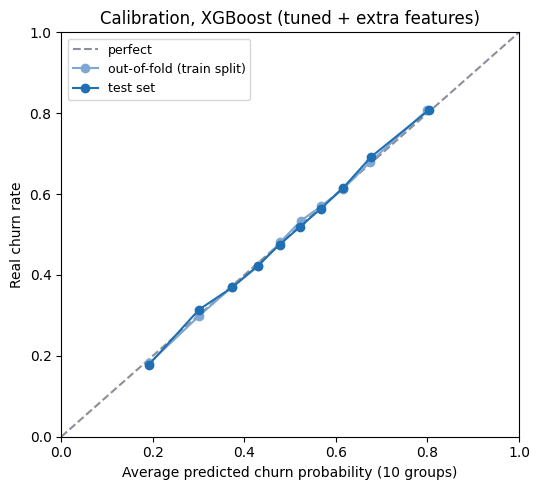

Brier score: test 0.2181, out-of-fold 0.2182, always predicting the average 0.2500


In [18]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.plot([0, 1], [0, 1], linestyle="--", color="#8A8F99", label="perfect")
for label, y_true, p, color in [("out-of-fold (train split)", y_train, oof, "#7FA7D3"),
                                ("test set", y_test, prob, "#1F6FB2")]:
    actual, predicted = calibration_curve(y_true, p, n_bins=10, strategy="quantile")
    ax.plot(predicted, actual, marker="o", color=color, label=label)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Average predicted churn probability (10 groups)")
ax.set_ylabel("Real churn rate")
ax.set_title(f"Calibration, {final_name}")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(FIG_DIR / "v2_calibration.png", dpi=150)
plt.show()

print(f"Brier score: test {brier_score_loss(y_test, prob):.4f}, out-of-fold {brier_score_loss(y_train, oof):.4f}, "
      f"always predicting the average {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f}")

The probabilities are for data where half the customers churn. At a real churn rate they have to be moved
down. With the same assumption as in 6.4 (the data was sampled, the ranking holds), only the odds change:
new odds = old odds × (real rate / (1 − real rate)) / (data rate / (1 − data rate)).
The table checks this on the test set re-weighted to 2% churn.

In [19]:
def adjust_to_churn_rate(p, data_rate, real_rate):
    odds = p / (1 - p) * (real_rate / (1 - real_rate)) / (data_rate / (1 - data_rate))
    return odds / (1 + odds)


prob_real = adjust_to_churn_rate(prob, y_train.mean(), REAL_CHURN_RATE)
check = pd.DataFrame({
    "average_adjusted_probability": pd.Series(prob_real).groupby(risk_group).mean(),
    "real_rate_at_2pct": real_rate,
})
check.index.name = "risk_group"
check.round(4)

,average_adjusted_probability,real_rate_at_2pct
risk_group,,
1,0.0893,0.0799
2,0.0419,0.0446
3,0.0322,0.0320
4,0.0265,0.0261
5,0.0222,0.0220
6,0.0186,0.0184
7,0.0154,0.0150
8,0.0123,0.0120
9,0.0089,0.0094


- The points sit on the diagonal for both the out-of-fold and the test predictions, so in this data a
  predicted 30% really means about 30% churn. The Brier score is 0.218, against 0.250 for always predicting
  the average.
- Moved to a 2% churn rate, the probabilities match the re-weighted churn rates well. Only the top group is a
  bit too high (8.9% predicted vs 8.0% real).
- So the probabilities can be used for the profit maths, as long as the real churn rate is plugged in.

## 9. Summary

| | Notebook 01 (submitted) | This notebook |
|---|---|---|
| Cleaning | medians from all customers | learned on training data only |
| Evaluation | one test split | 5-fold CV (mean ± std) + the same test split |
| Baselines | none | device-age rule (0.55), logistic regression (0.63) |
| XGBoost settings | fixed by hand | tuned with Optuna (gain of about 0.001-0.003) |
| Features | original + 2 trend ratios | + 13 ratio features in 4 groups (gain of about 0.005) |
| Test ROC-AUC | 0.6952 | 0.7026 |
| Threshold | picked on the test set | picked on out-of-fold data, reported on the test set |
| Profit model | every offered churner stays, saved value counted twice | success rate, one value per customer, compared with "offer everyone" |
| Calibration | not checked | predicted ≈ real churn rate (Brier 0.218) |

Main points:

- XGBoost ranks customers clearly better than the simple baselines. Tuning added about 0.001 and the extra
  features about 0.005, so better inputs mattered more than settings. ROC-AUC is still only about 0.70.
- The profit result in the proposal came mostly from the assumptions. With half the customers churning,
  offering everyone is almost as good as using the model. With a realistic churn rate, the $35 offer only pays
  off for the highest-risk group and only with a high success rate.
- `scripts/train.py` and `scripts/score_customers.py` turn this into a repeatable process: train, pick the
  threshold, then score customers with their top reasons and a suggested offer.